In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from scipy.stats import mannwhitneyu, spearmanr
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.outliers_influence import variance_inflation_factor
import statsmodels.api as sm

DATA_DIR = Path.cwd() / "data" / "processed"

buildings = pd.read_parquet(DATA_DIR / "buildings.parquet")

df = buildings.drop_duplicates(subset="bin").copy()
df = df[df["in_lower_manhattan"] == True].copy()

df["has_testing"] = (df["n_test_pages"] > 0).astype(int)

size_columns = [
    "building_area_sqft",
    "floors",
    "year_built",
    "total_units",
    "residential_units"
]

print("Total buildings:", len(df))
print("Buildings with records:", df["has_testing"].sum())
print("Buildings without records:", (df["has_testing"] == 0).sum())

Total buildings: 970
Buildings with records: 345
Buildings without records: 625


In [2]:
quality = pd.DataFrame({
    "non_missing": df[size_columns].notna().sum(),
    "missing": df[size_columns].isna().sum(),
    "missing_rate": df[size_columns].isna().mean() * 100
})

display(quality.round(2))

display(df[size_columns].describe().T.round(2))

,non_missing,missing,missing_rate
building_area_sqft,883,87,8.97
floors,878,92,9.48
year_built,881,89,9.18
total_units,871,99,10.21
residential_units,536,434,44.74


,count,mean,std,min,25%,50%,75%,max
building_area_sqft,883.0,162268.616082,360146.393804,424.0,9108.0,20882.0,125500.0,3553553.0
floors,878.0,13.45672,19.36871,1.0,5.0,6.0,16.0,325.0
year_built,881.0,1911.164586,46.312539,1719.0,1885.0,1910.0,1931.0,2024.0
total_units,871.0,51.156142,157.158507,1.0,4.0,6.0,26.0,1722.0
residential_units,536.0,67.102612,192.919795,1.0,4.0,6.0,24.0,1712.0


In [3]:
# Parametric test: Mann Whitney u test 
presence_results = []

for col in size_columns:
    tested = df.loc[df["has_testing"] == 1, col].dropna()
    untested = df.loc[df["has_testing"] == 0, col].dropna()

    stat, p = mannwhitneyu(
        tested,
        untested,
        alternative="two-sided"
    )

    presence_results.append({
        "characteristic": col,
        "tested_n": len(tested),
        "untested_n": len(untested),
        "tested_median": tested.median(),
        "untested_median": untested.median(),
        "p_value": p
    })

presence_results = pd.DataFrame(presence_results)

presence_results["p_adjusted"] = multipletests(
    presence_results["p_value"],
    method="holm"
)[1]

display(presence_results.round(5))

,characteristic,tested_n,untested_n,tested_median,untested_median,p_value,p_adjusted
0,building_area_sqft,322,561,29994.5,18314.0,0.00001,0.00005
1,floors,319,559,6.0,6.0,0.00047,0.00140
2,year_built,322,559,1915.0,1905.0,0.00001,0.00005
3,total_units,315,556,7.0,6.0,0.00120,0.00241
4,residential_units,187,349,7.0,6.0,0.06193,0.06193


In [4]:
# Parametric test: Welch's t-test
from scipy.stats import ttest_ind
from statsmodels.stats.multitest import multipletests


ttest_results = []

for col in size_columns:
    temp = df[[col, "has_testing"]].copy()
    temp[col] = pd.to_numeric(temp[col], errors="coerce")
    temp = temp.dropna()

    tested = temp.loc[temp["has_testing"] == True, col]
    not_tested = temp.loc[temp["has_testing"] == False, col]

    t_stat, p_value = ttest_ind(
        tested,
        not_tested,
        equal_var=False
    )

    ttest_results.append({
        "characteristic": col,
        "n_tested": len(tested),
        "n_not_tested": len(not_tested),
        "mean_tested": tested.mean(),
        "mean_not_tested": not_tested.mean(),
        "t_statistic": t_stat,
        "p_value": p_value
    })

ttest_results = pd.DataFrame(ttest_results)

ttest_results["p_adjusted"] = multipletests(
    ttest_results["p_value"],
    method="holm"
)[1]

display(ttest_results.round(5))

,characteristic,n_tested,n_not_tested,mean_tested,mean_not_tested,t_statistic,p_value,p_adjusted
0,building_area_sqft,322,561,207480.72671,136317.99287,2.79200,0.00540,0.02158
1,floors,319,559,15.13793,12.49732,1.91202,0.05633,0.16899
2,year_built,322,559,1919.12112,1906.58140,3.88435,0.00011,0.00056
3,total_units,315,556,62.01905,45.00180,1.55591,0.12020,0.24039
4,residential_units,187,349,82.28877,58.96562,1.36339,0.17352,0.24039


In [5]:
#Correlation analysis
count_results = []

for col in size_columns:
    temp = df[[col, "n_test_pages"]].dropna()

    rho, p = spearmanr(
        temp[col],
        temp["n_test_pages"]
    )

    count_results.append({
        "characteristic": col,
        "n": len(temp),
        "spearman_rho": rho,
        "p_value": p
    })

count_results = pd.DataFrame(count_results)

count_results["p_adjusted"] = multipletests(
    count_results["p_value"],
    method="holm"
)[1]

display(count_results.round(5))

,characteristic,n,spearman_rho,p_value,p_adjusted
0,building_area_sqft,883,0.20482,0.00000,0.00000
1,floors,878,0.16017,0.00000,0.00001
2,year_built,881,0.17892,0.00000,0.00000
3,total_units,871,0.12637,0.00018,0.00037
4,residential_units,536,0.14003,0.00115,0.00115


,building_area_sqft,floors,year_built,total_units,residential_units
building_area_sqft,1.000,0.757,0.514,0.590,0.873
floors,0.757,1.000,0.415,0.517,0.664
year_built,0.514,0.415,1.000,0.217,0.406
total_units,0.590,0.517,0.217,1.000,0.956
residential_units,0.873,0.664,0.406,0.956,1.000


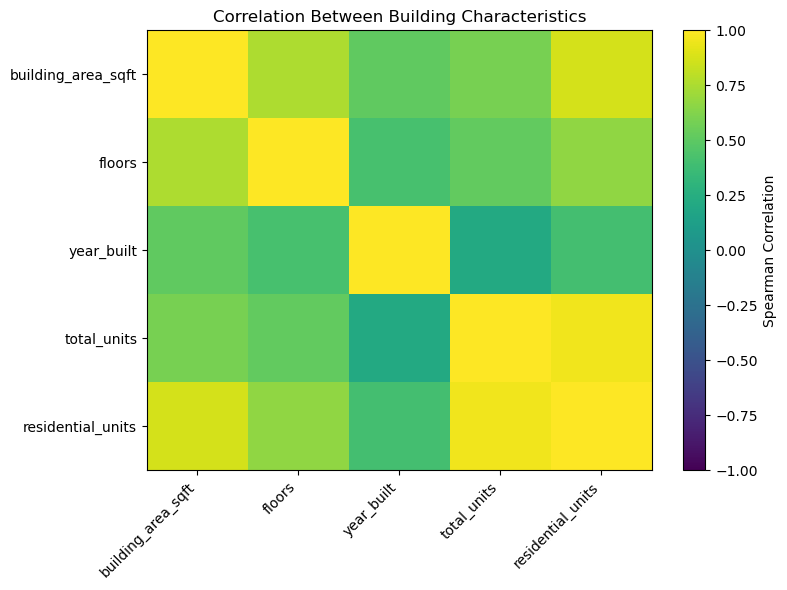

In [6]:
# Draw the correlation graph
correlation_matrix = df[size_columns].corr(
    method="spearman"
)

display(correlation_matrix.round(3))

plt.figure(figsize=(8, 6))

plt.imshow(
    correlation_matrix,
    vmin=-1,
    vmax=1,
    aspect="auto"
)

plt.xticks(
    range(len(size_columns)),
    size_columns,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(len(size_columns)),
    size_columns
)

plt.colorbar(label="Spearman Correlation")
plt.title("Correlation Between Building Characteristics")

plt.tight_layout()
plt.show()

In [7]:
# Logit Regression analysis
model_columns = [
    "building_area_sqft",
    "floors",
    "year_built"
]

model_df = df[
    model_columns + ["has_testing"]
].copy()

# Convert columns to numeric
for col in model_columns:
    model_df[col] = pd.to_numeric(
        model_df[col],
        errors="coerce"
    )

model_df = model_df.dropna().copy()

# Log-transform building area
model_df["log_building_area"] = np.log1p(
    model_df["building_area_sqft"]
)

# Standardize predictors
X = model_df[
    ["log_building_area", "floors", "year_built"]
].astype(float)

X = (X - X.mean()) / X.std()

X = sm.add_constant(X)

# Explicitly convert outcome to integer
y = model_df["has_testing"].astype(int)

# Fit logistic regression
logit_model = sm.Logit(y, X).fit()

print("Sample size:", len(model_df))
print(logit_model.summary())

Optimization terminated successfully.
         Current function value: 0.642615
         Iterations 5
Sample size: 877
                           Logit Regression Results                           
Dep. Variable:            has_testing   No. Observations:                  877
Model:                          Logit   Df Residuals:                      873
Method:                           MLE   Df Model:                            3
Date:                Sat, 28 Nov 2026   Pseudo R-squ.:                 0.01972
Time:                        12:11:35   Log-Likelihood:                -563.57
converged:                       True   LL-Null:                       -574.91
Covariance Type:            nonrobust   LLR p-value:                 4.731e-05
                        coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------
const                -0.5730      0.071     -8.032      0.000      -0.713    